# Кейс «Кофейня»: case Sber

Сценарий: **одинаковая** цена напитка (250 руб.), разные **себестоимости**: сорт A - 50 руб., сорт B - 80 руб.

**Маржинальный доход**: от сорта А - 200р, от сорта В - 170р.

**Цель кейса** - понять влияет ли сорт кофе на предпочтения клиентов, и выбрать один сорт для продажи.

**Основная цель эксперемента** - проверить, связан ли сорт с вероятностью повторного визита в течение 30 дней.

> Ограничение: повторный визит - условный показатель удовлетворённости. Он зависит не только от сорта кофе, но и от расстояния до кофейни, привычек, графика, качества сервиса и других факторов.

## 1 Дизайн эксперимента

- **Единица измерения:** уникальный клиент.
- **Контроль:** сорт A (текущий сорт); **эксперимент:** сорт B (новый сорт).
- **Распределение:** случайное 1:1. Назначеная группа сохраняется за клиентом на весь период эксперемента.
- **Рандомизация:** клиенту не сообщают сорт. По возможности стандартизировать рецепт, объём, температуру и подачу.
- **Основная метрика:** доля участников с ≥1 повторным визитом в течение 30 дней от первого визита.
- **Вторичные метрики:** конверсия в покупку, маржинальная прибыль на участника; средний чек;
- **Защитные метрики:** число жалоб/возвратов; время обслуживания; churn rate
- **Гипотезы:** H0: pA = pB; H1: pA ≠ pB. Двусторонний Z-тест для двух пропорций.
- **Уровень значимости:** α = 0,05; **мощность:** 80%.
- **MDE:** с 20% до 25%, то есть +5 процентных пунктов. Это планируемый минимальный эффект, который планируется обнаруживать.
- **Общее количество записей:** 5000.
- **Размер выборки:** ориентировочно около 1 200 клиентов на группу для сравнения 20% и 25% при α=0,05 и мощности 80%;
> Размер выборки составлен при учете, что в день приходит ~170 новых клиентов.
- **Период проведения эксперемента:** ~44 дней.
> Период проведения эксперемента больше, чем проведение стандартного A/B теста, так как данные должны показывать доли **повторных визитов** клиентов.

In [ ]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Исходные параметры эксперимента
p_a = 0.20
p_b = 0.25
alpha = 0.05
power = 0.80
ratio = 1.0

effect_size = abs(proportion_effectsize(p_a, p_b))
analysis = NormalIndPower()

n_per_group = int(analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=ratio,
    alternative="two-sided"
))

total_sample = n_per_group * 2

print(f"Размер группы A: {n_per_group}")
print(f"Размер группы B: {n_per_group}")
print(f"Общий размер выборки: {total_sample}")

Размер группы A: 1091
Размер группы B: 1091
Общий размер выборки: 2182


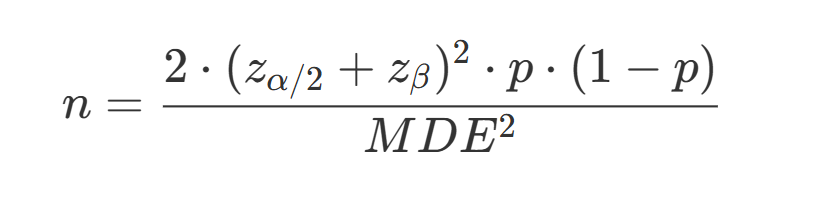

### Разделение на сегменты

- **Время визита:** утренние до 11, обеденные с 12 до 17, вечерние с 17 до закрытия
- **Возраст:** молодые до 25, взрослые с 26 до 45, старшие с 46
- **По способу покупки:** заказ в приложении или в кофейне

Сама сегментация **не повлияет** на результаты A/B теста. Однако она поможет проанализировать дальнейшие гипотезы о предпочтениях разных возрастных или временных групп, а также гипотезы об использовании приложения для заказа кофе.

### 2 Проведение эксперемента
В идеале каждый клиент должен иметь уникальный ID в приложении, чтобы система автоматически присваивала ему группу для дегустации кофе. Однако на практике не у всех есть приложение или карта лояльности.

Предлагаю заводить таким клиентам бумажную анкету-карточку с уникальным номером. В период эксперимента эта карточка также дает скидку на кофе (как и QR-код в приложении).

**Процесс работы бариста**:

- Бариста сканирует QR-код карточки клиента.

- Вносит в систему телефон и дату рождения (для того, чтобы рекомендовать акции в праздник и узнать возраст)

- Система запоминает эти данные.

**Результат**:
При следующих визитах система автоматически определяет, какой сорт кофе предложить этому конкретному клиенту. В приложении этот выбор происходит автоматически.

### Синтетические данные

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

all_df = pd.read_excel("/content/sample_data/coffee_ab_test_5000_population_2400_experiment.xlsx", sheet_name="Population_5000")
df = pd.read_excel("/content/sample_data/coffee_ab_test_5000_population_2400_experiment.xlsx", sheet_name="Experiment_2400")

In [ ]:
all_df.head(10)

,participant_id,first_visit_date,age,age_segment,visit_time,visit_time_segment,purchase_method,experiment_status
0,P00001,2026-09-01,29,Взрослые,11:17,Утро,Приложение,0
1,P00002,2026-09-12,53,Старшие,10:23,Утро,Приложение,0
2,P00003,2026-09-06,68,Старшие,13:14,Обед,Приложение,0
3,P00004,2026-09-10,52,Старшие,18:24,Вечер,Приложение,A
4,P00005,2026-09-03,64,Старшие,14:48,Обед,Кофейня,0
5,P00006,2026-09-09,41,Взрослые,10:13,Утро,Кофейня,B
6,P00007,2026-09-05,52,Старшие,09:09,Утро,Кофейня,B
7,P00008,2026-09-08,63,Старшие,13:45,Обед,Приложение,0
8,P00009,2026-09-10,38,Взрослые,20:46,Вечер,Приложение,0
9,P00010,2026-09-12,64,Старшие,16:23,Обед,Кофейня,0


In [ ]:
df.head(10)

,participant_id,group,first_visit_date,returned_within_30d,repeat_visits_30d,price_rub,cost_per_cup_rub,age,age_segment,visit_time,visit_time_segment,purchase_method,experiment_status
0,P00004,A,2026-09-10,1,1,250,50,52,Старшие,18:24,Вечер,Приложение,Группа A
1,P00011,A,2026-09-10,0,0,250,50,22,Молодые,16:19,Обед,Приложение,Группа A
2,P00012,A,2026-09-08,0,0,250,50,62,Старшие,09:41,Утро,Приложение,Группа A
3,P00013,A,2026-09-13,0,0,250,50,19,Молодые,16:15,Обед,Кофейня,Группа A
4,P00028,A,2026-09-04,0,0,250,50,41,Взрослые,13:54,Обед,Кофейня,Группа A
5,P00042,A,2026-09-10,1,3,250,50,20,Молодые,16:09,Обед,Кофейня,Группа A
6,P00047,A,2026-09-04,0,0,250,50,48,Взрослые,17:48,Вечер,Кофейня,Группа A
7,P00057,A,2026-09-08,1,2,250,50,67,Старшие,09:22,Утро,Кофейня,Группа A
8,P00066,A,2026-09-05,0,0,250,50,53,Старшие,13:53,Обед,Кофейня,Группа A
9,P00068,A,2026-09-09,0,0,250,50,39,Взрослые,19:42,Вечер,Кофейня,Группа A


## Проверка выборки на однородность и репрезентативность

In [ ]:
from scipy.stats import chi2_contingency

features = ["age_segment", "visit_time_segment", "purchase_method"]

for feature in features:
    table = pd.crosstab(df["group"], df[feature])

    chi2, p_value, dof, expected = chi2_contingency(table)

    print(f"\nПризнак: {feature}")
    print(table)
    print(f"p-value = {p_value:.4f}")

    if p_value < 0.05:
        print("Обнаружено статистически значимое различие.")
    else:
        print("Статистически значимое различие не обнаружено.")


Признак: age_segment
age_segment  Взрослые  Молодые  Старшие
group                                  
A                 559      165      476
B                 551      169      480
p-value = 0.9407
Статистически значимое различие не обнаружено.

Признак: visit_time_segment
visit_time_segment  Вечер  Обед  Утро
group                                
A                     374   485   341
B                     375   460   365
p-value = 0.4775
Статистически значимое различие не обнаружено.

Признак: purchase_method
purchase_method  Кофейня  Приложение
group                               
A                    683         517
B                    739         461
p-value = 0.0223
Обнаружено статистически значимое различие.



Возраст
p-value = 0.9407
Статистически значимых различий не обнаружено

Время посещения
p-value = 0.4775
Статистически значимых различий не обнаружено

Способ покупки
p-value = 0.0223
Распределения групп статистически различаются


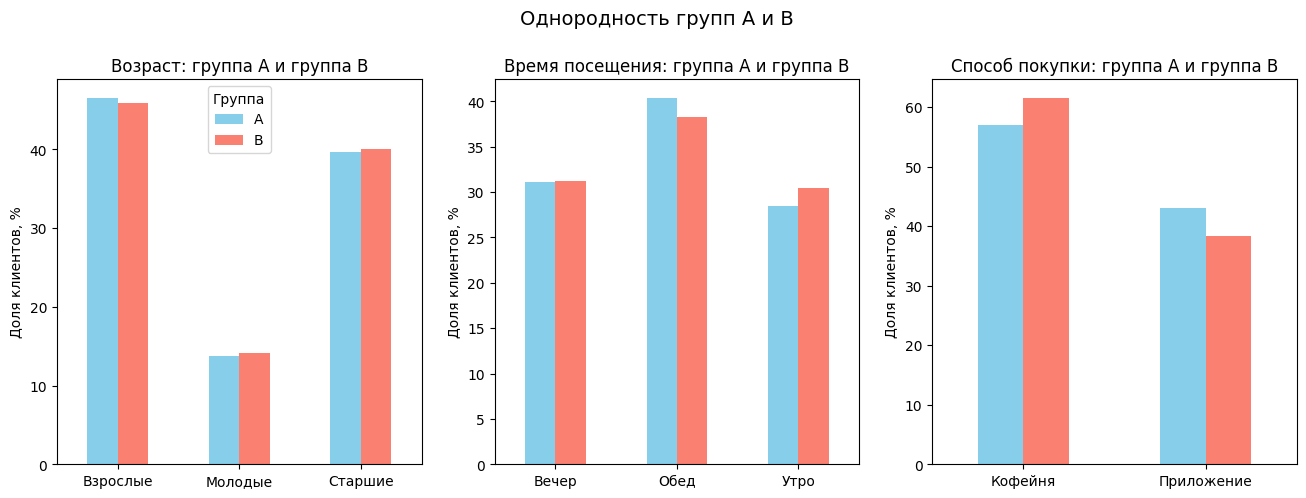

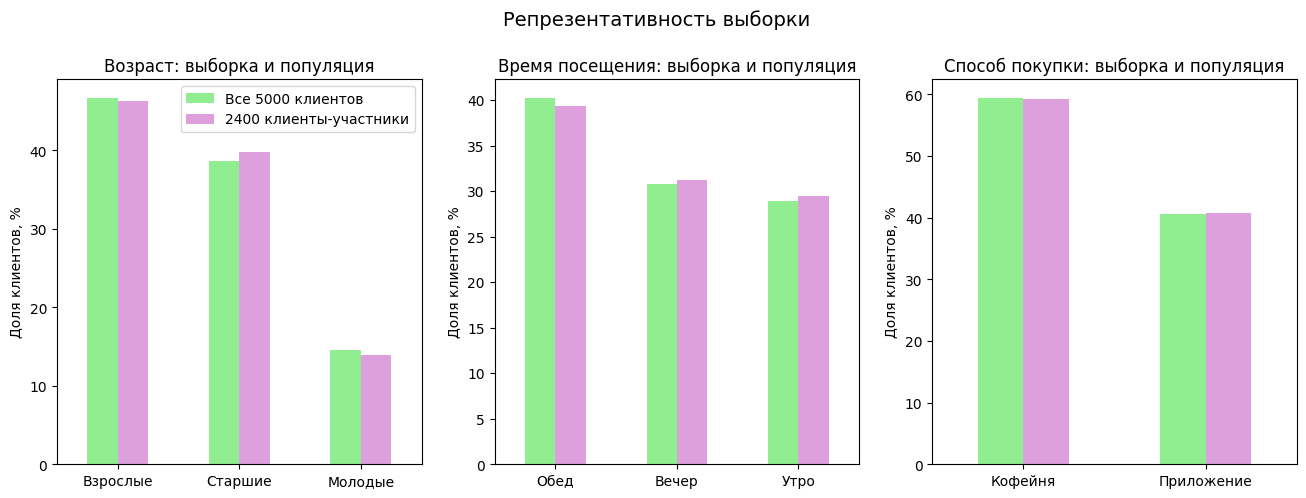

In [ ]:
import matplotlib.pyplot as plt

features = {
    "age_segment": "Возраст",
    "visit_time_segment": "Время посещения",
    "purchase_method": "Способ покупки"
}

fig1, axes1 = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))
fig2, axes2 = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))

colors = ["skyblue", "salmon", "lightgreen", "plum", "gold"]

for i, (column, title) in enumerate(features.items()):
    ax = axes1[i]

    table = pd.crosstab(
        df[column],
        df["group"],
        normalize="columns"
    ) * 100

    table.plot(
        kind="bar",
        color=["skyblue", "salmon"],
        ax=ax,
        legend=(i == 0)
    )

    ax.set_title(f"{title}: группа A и группа B")
    ax.set_ylabel("Доля клиентов, %")
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=0)
    if i == 0:
        ax.legend(title="Группа")

    # Статистика
    counts = pd.crosstab(df["group"], df[column])
    chi2, p, dof, expected = chi2_contingency(counts)

    print(f"\n{title}")
    print(f"p-value = {p:.4f}")
    if p < 0.05:
        print("Распределения групп статистически различаются")
    else:
        print("Статистически значимых различий не обнаружено")


for i, (column, title) in enumerate(features.items()):
    ax = axes2[i]

    comparison = pd.DataFrame({
        "Все 5000 клиентов": population[column].value_counts(normalize=True) * 100,
        "2400 клиенты-участники": df[column].value_counts(normalize=True) * 100
    }).fillna(0)

    comparison.plot(
        kind="bar",
        color=["lightgreen", "plum"],
        ax=ax,
        legend=(i == 0)  # Легенда только на первом графике
    )

    ax.set_title(f"{title}: выборка и популяция")
    ax.set_ylabel("Доля клиентов, %")
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=0)
    if i == 0:
        ax.legend()

fig1.suptitle("Однородность групп A и B", fontsize=14, y=1.02)
fig2.suptitle("Репрезентативность выборки", fontsize=14, y=1.02)

plt.show()


In [ ]:
summary = df.groupby("group").agg(
    participants=("participant_id", "nunique"),
    returned=("returned_within_30d", "sum")
)
summary["return_rate"] = summary["returned"] / summary["participants"]
summary


,participants,returned,return_rate
group,,,
A,1200,231,0.1925
B,1200,297,0.2475


In [ ]:
counts = summary.loc[["A", "B"], "returned"].to_numpy()
nobs = summary.loc[["A", "B"], "participants"].to_numpy()
z_stat, p_value = proportions_ztest(counts, nobs, alternative="two-sided")

p_a = counts[0] / nobs[0]
p_b = counts[1] / nobs[1]
difference = p_b - p_a
se = np.sqrt(p_a*(1-p_a)/nobs[0] + p_b*(1-p_b)/nobs[1])
ci_low, ci_high = difference - 1.96*se, difference + 1.96*se

print(f"Возврат A: {p_a:.2%}")
print(f"Возврат B: {p_b:.2%}")
print(f"Разница B-A: {difference:.2%} ({difference*100:.2f} п.п.)")
print(f"Z-статистика: {z_stat:.3f}")
print(f"p-value: {p_value:.4f}")
print(f"Приблизительный 95% ДИ разницы: [{ci_low*100:.2f}; {ci_high*100:.2f}] п.п.")


Возврат A: 19.25%
Возврат B: 24.75%
Разница B-A: 5.50% (5.50 п.п.)
Z-статистика: -3.252
p-value: 0.0011
Приблизительный 95% ДИ разницы: [2.19; 8.81] п.п.


В группе A за 30 дней вернулись 231 человек (~19%) в группе B - 297 человек (25%).

### Интерпретация

В синтетическом примере **доля возвратов** в группе A составляет 19,25%, в группе B - 24,75%; разница - около 5,5 п.п. **p-value ≈ 0,0011**, что ниже 0,05. Поэтому в этом эксперементе **отвергаем H0** и фиксируем статистически значимое различие долей возврата.

Приблизительный 95% доверительный интервал разницы B−A - около 1,6–8,5 п.п. Статистическая значимость не доказывает, что вкус - единственная причина возврата; это требует одинаковых условий и качественной рандомизации.


In [ ]:
price = 250
costs = {"A": 50, "B": 80}
margins = {g: price-costs[g] for g in costs}

economic = []
for g in ["A", "B"]:
    n_g = int(summary.loc[g, "participants"])
    ret_g = int(summary.loc[g, "returned"])
    total_cups = n_g + ret_g
    profit = total_cups * margins[g]
    economic.append({
        "group": g, "participants": n_g, "returns": ret_g,
        "price": price, "cost": costs[g], "margin_per_cup": margins[g],
        "cups_modelled": total_cups, "contribution_profit": profit,
        "profit_per_participant": profit/n_g
    })
pd.DataFrame(economic)


,group,participants,returns,price,cost,margin_per_cup,cups_modelled,contribution_profit,profit_per_participant
0,A,1200,231,250,50,200,1431,286200,238.500
1,B,1200,297,250,80,170,1497,254490,212.075


## 3 Выводы и рекомендации

### Интерпретация экономики

При цене 250 руб. маржа с чашки сорта A равна 200 руб., сорта B — 170 руб. В упрощённой модели (одна первоначальная покупка и максимум одна дополнительная чашка у вернувшихся) прибыль на участника:
- A: 200 × (1 + 0,1925) = 238,500 руб.
- B: 170 × (1 + 0,2475) ≈ 212,075 руб.

Получается, что A выгоднее, даже несмотря на то, что за B чаще возвращаются. Это демонстрирует, почему нельзя принимать решение только по одной метрике. В реальном анализе нужно считать фактическое количество покупок и переменные затраты, а также учитывать списания, зарплатные/операционные расходы и возможную разницу в размере заказа.

## 6. Рекомендация и ограничения

- **Выбрать сорт A** для продажи с точки зрения экономической эффективности. Несмотря на то что **сорт B** показал более высокую долю повторных визитов (24,75% против 19,25% у сорта A), сорт A имеет более низкую себестоимость чашки. Поэтому при заданных условиях сорт A выглядит более выгодным с точки зрения дохода с каждой проданной чашки.

- **Продлить эксперемент**. Так как тест на синтетических данных не дал однозначных результатов, следует продлить эксперемент, и на реальных данных убедиться какой сорт кофе оставить наиболее выгодно.

- **Проверить возможность повышения цены сорта B**. Если поставить кружке кофе из сорта В стоимость в 280р, соответственно маржинальная прибыль с чашки составит 200р - столько же, сколько у сорта А. Следует провести отдельный A/B-тест, сравнив сорт B по цене 250 и 280 рублей. Основное внимание нужно уделить маржинальному доходу на клиента, а также проверить, не приведёт ли повышение цены к снижению количества покупок и доли повторных визитов.

- **Учитывать ограничения исследования**. На повторные визиты могут влиять не только сорт кофе, но и обслуживание, время посещения, цена и другие факторы. Поэтому в реальном эксперименте важно контролировать условия тестирования и не приписывать весь эффект вкусу кофе, если одновременно менялись другие параметры.

# Итоговая рекомендация

В синтетическом примере сорт B лучше по доле повторных визитов, что было выбрано основной метрикой, однако **сорт A выгоднее по маржинальному доходу** с одной чашки. Поэтому при приоритете текущей экономики продаж рекомендуется выбрать сорт A. Перед внедрением решения желательно проверить, сможет ли более высокая частота повторных покупок сорта B компенсировать его повышенную себестоимость на реальных данных.